In [ ]:
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

# --- make every graph pretty + interactive (set once, applies everywhere) ---
%matplotlib inline
plt.style.use("bmh")
plt.rcParams.update(
    {"figure.figsize": (10, 5), "figure.dpi": 300, "lines.linewidth": 1.6}
)

Цена актива $P_t$;

Работаем в log-ценах:

$$
S_t = \log P_t.
$$.

$\Delta t$ -- маленький шаг по времени, $\Delta S_i$ -- приращение лог-цены $S_t$ за этот шаг по времени.
$$


# Synthetic Data


In [2]:
def calc_gauss_ds(
    mu: float = 0.0,
    sigma: float = 1.0,
    dt: float = 1e-3,
) -> float:
    return mu * dt + sigma * np.sqrt(dt) * np.random.normal()


def calc_gauss_path(
    dt: float = 1e-3,
    mu: Callable[[list[float], float], float] = lambda s, t: 0.0,
    sigma: Callable[[list[float], float], float] = lambda s, t: 1.0,
) -> np.ndarray:
    time = np.arange(0, 1, dt)
    path = np.zeros_like(time)
    for i in range(1, len(time)):
        path[i] = path[i - 1] + calc_gauss_ds(
            mu=mu(path[:i], time[i]), sigma=sigma(path[:i], time[i]), dt=dt
        )
    return time, path


def calc_general_path(
    time_grid: np.ndarray,
    mu: Callable[[list[float], float], float] = lambda s, t: 0.0,
    sigma: Callable[[list[float], float], float] = lambda s, t: 1.0,
    distribution: Callable[[], float] = lambda: np.random.normal(),
    alpha: float = 0.5,
) -> np.ndarray:
    time = time_grid
    path = np.zeros_like(time)
    for i in range(1, len(time)):
        dt = time[i] - time[i - 1]
        ds = (
            mu(path[:i], time[i]) * dt
            + sigma(path[:i], time[i]) * np.power(dt, alpha) * distribution()
        )
        path[i] = path[i - 1] + ds
    return path


def calc_general_paths(
    num_paths: int,
    time_grid: np.ndarray,
    mu: Callable[[list[float], float], float] = lambda s, t: 0.0,
    sigma: Callable[[list[float], float], float] = lambda s, t: 1.0,
    distribution: Callable[[], float] = lambda: np.random.normal(),
    alpha: float = 0.5,
) -> np.ndarray:
    paths = np.zeros((num_paths, len(time_grid)))
    for i in range(num_paths):
        paths[i] = calc_general_path(
            time_grid=time_grid,
            mu=mu,
            sigma=sigma,
            distribution=distribution,
            alpha=alpha,
        )
    return paths


def calc_paths_params(time_grid: np.ndarray, paths: np.ndarray) -> dict:
    mean = np.mean(paths[:, -1], axis=0)
    variance = np.var(paths[:, -1], axis=0)
    return {"mean": mean, "variance": variance}

/var/folders/wf/162bsgg10bbc8lvgn7cxh05r0000gn/T/ipykernel_38769/2270920626.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.figure.legend(loc="upper left")


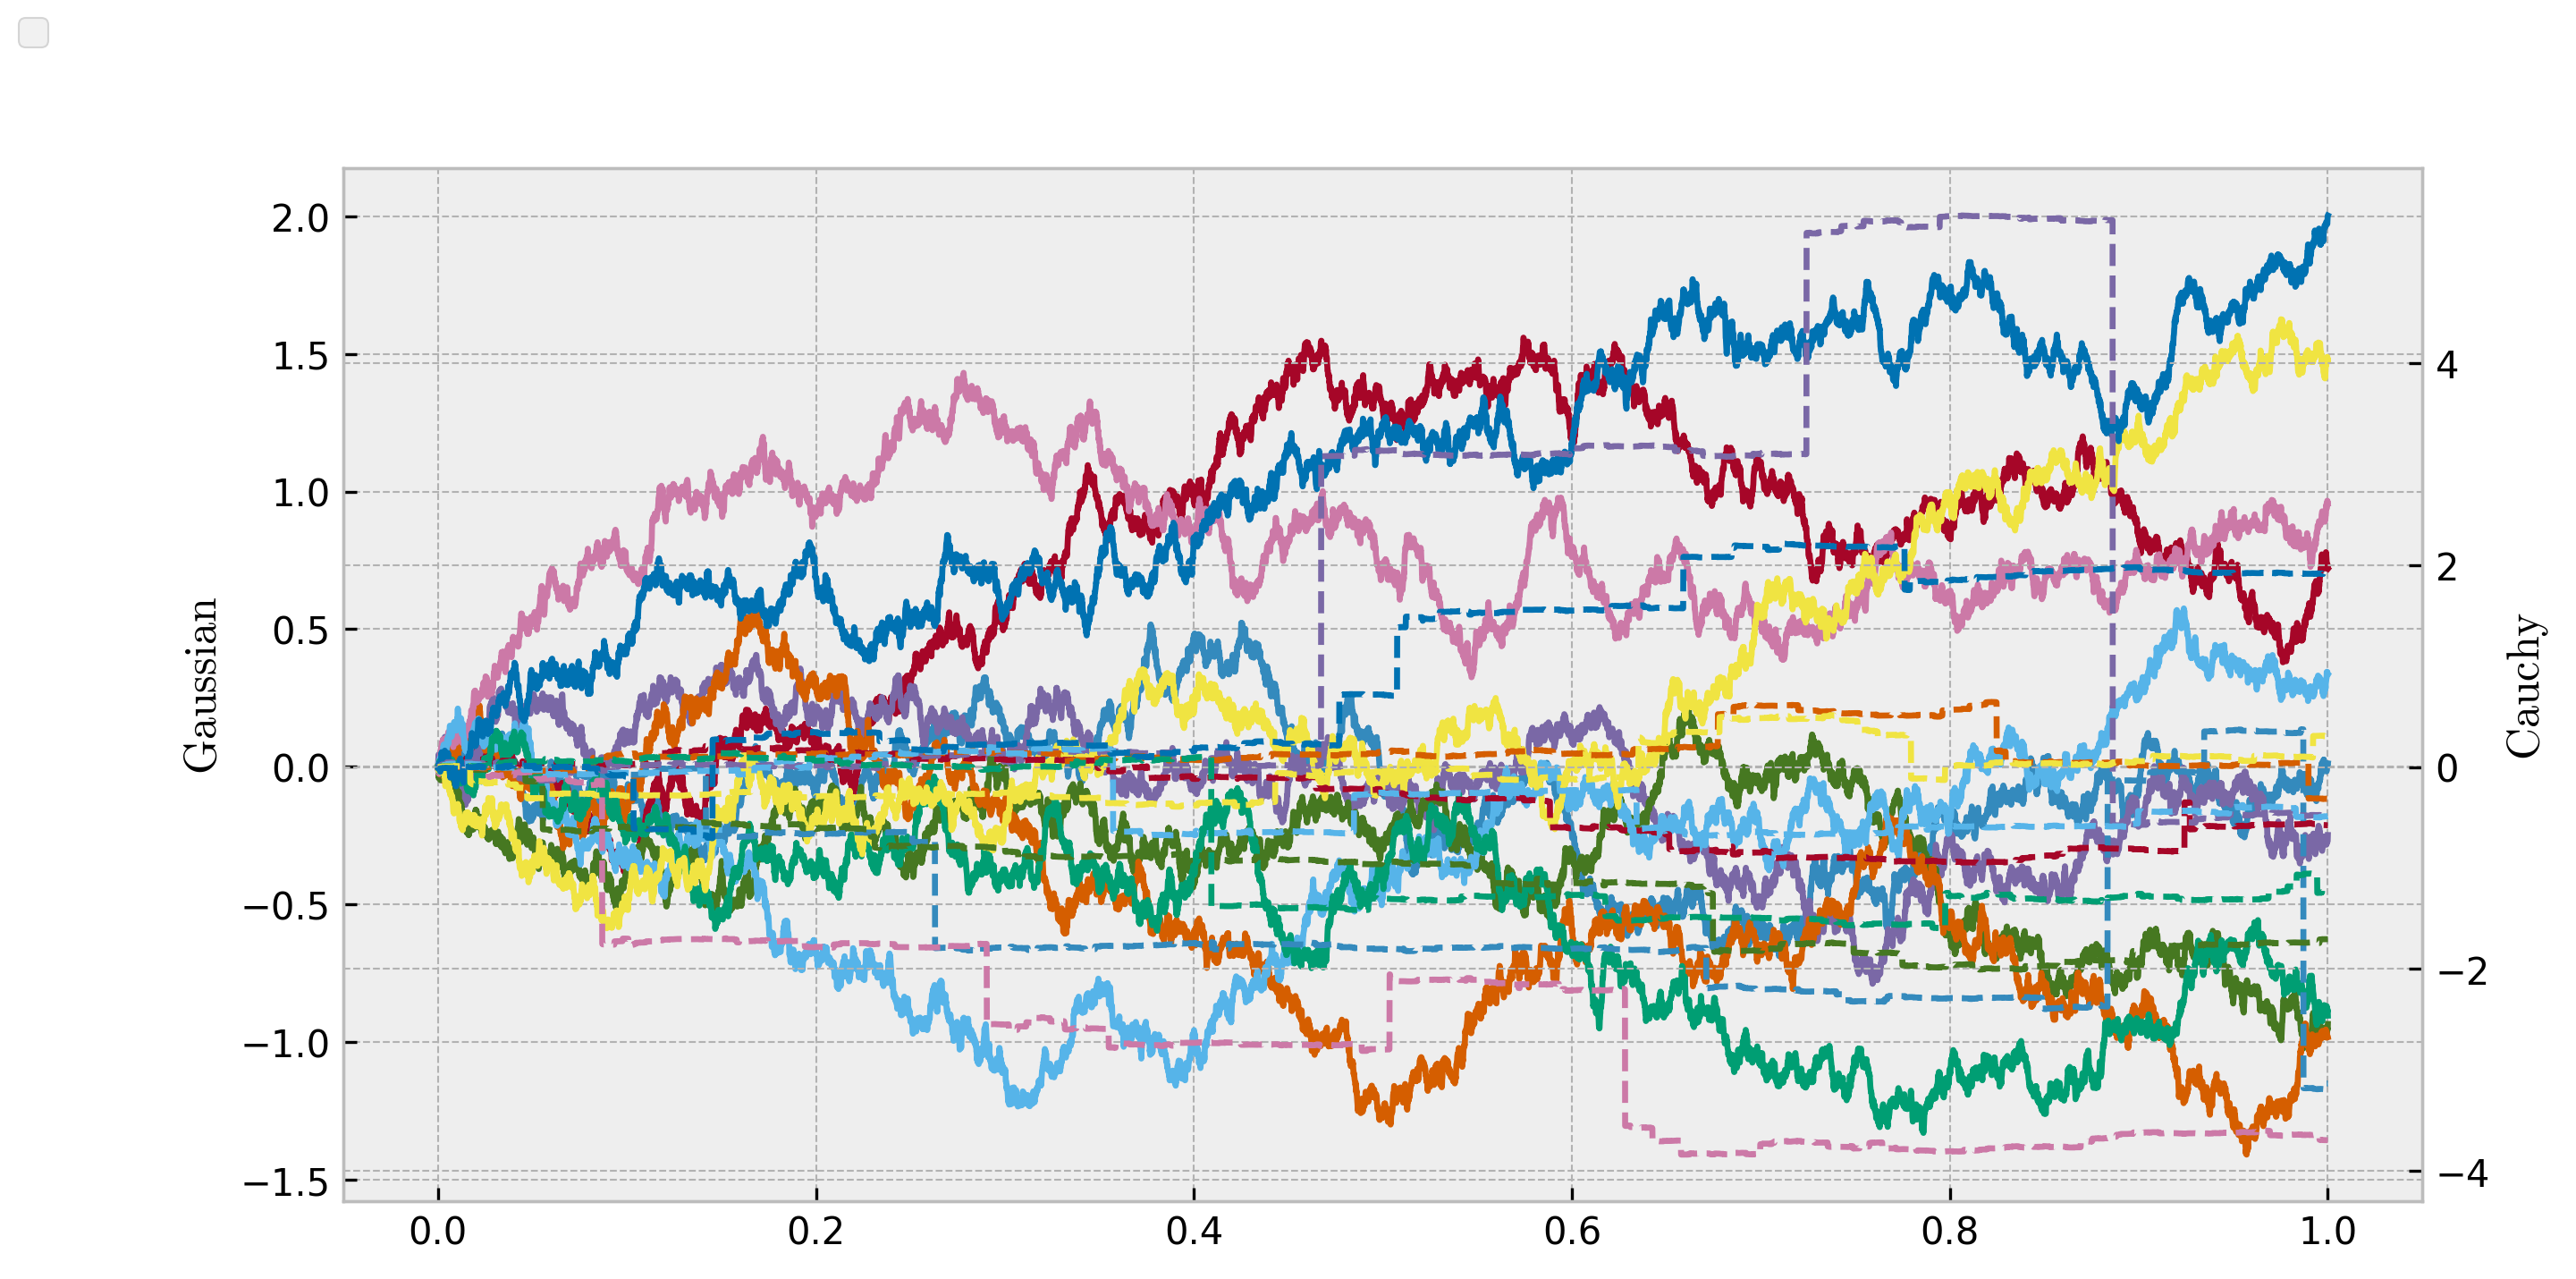

In [3]:
data = {
    "gauss": ...,
    "cauchy": ...,
}

time_uniform = np.linspace(0, 1, 10_000)
gpaths = calc_general_paths(
    num_paths=10,
    time_grid=time_uniform,
    distribution=lambda: np.random.normal(),
    alpha=0.5,
)
cpaths = calc_general_paths(
    num_paths=10,
    time_grid=time_uniform,
    distribution=lambda: np.random.standard_cauchy(),
    alpha=1.0,
)

ax = plt.subplots()[1]
ax_c = ax.twinx()
for gpath, cpath in zip(gpaths, cpaths):
    ax.plot(time_uniform, gpath, "-")
    ax_c.plot(time_uniform, cpath, "--")
ax.set_ylabel(r"$\text{Gaussian}$")
ax_c.set_ylabel(r"$\text{Cauchy}$")
ax.figure.legend(loc="upper left")
plt.show()

In [4]:
def var_st_vs_dt(alphas, dts, T, distribution, dss_num):
    results = {}
    for alpha in alphas:
        variances = []
        medians = []
        for dt in dts:
            dss_len = max(1, int(T / dt))
            ds = np.power(dt, alpha) * distribution(size=(dss_num, dss_len))
            st = ds.sum(axis=1)
            medians.append(np.median(np.abs(st)))
            variances.append(st.var())
        results[alpha] = {"vars": variances, "meds": medians}
    return results


rng = np.random.default_rng(42)
alphas = [0.1, 0.2, 0.5, 0.8, 1.0, 1.5]
dss_num = 10_000
dts = np.logspace(-4, -1, 12)
T = 1.0

results_gauss = var_st_vs_dt(alphas, dts, T, rng.standard_normal, dss_num)
results_cauchy = var_st_vs_dt(alphas, dts, T, rng.standard_cauchy, dss_num)

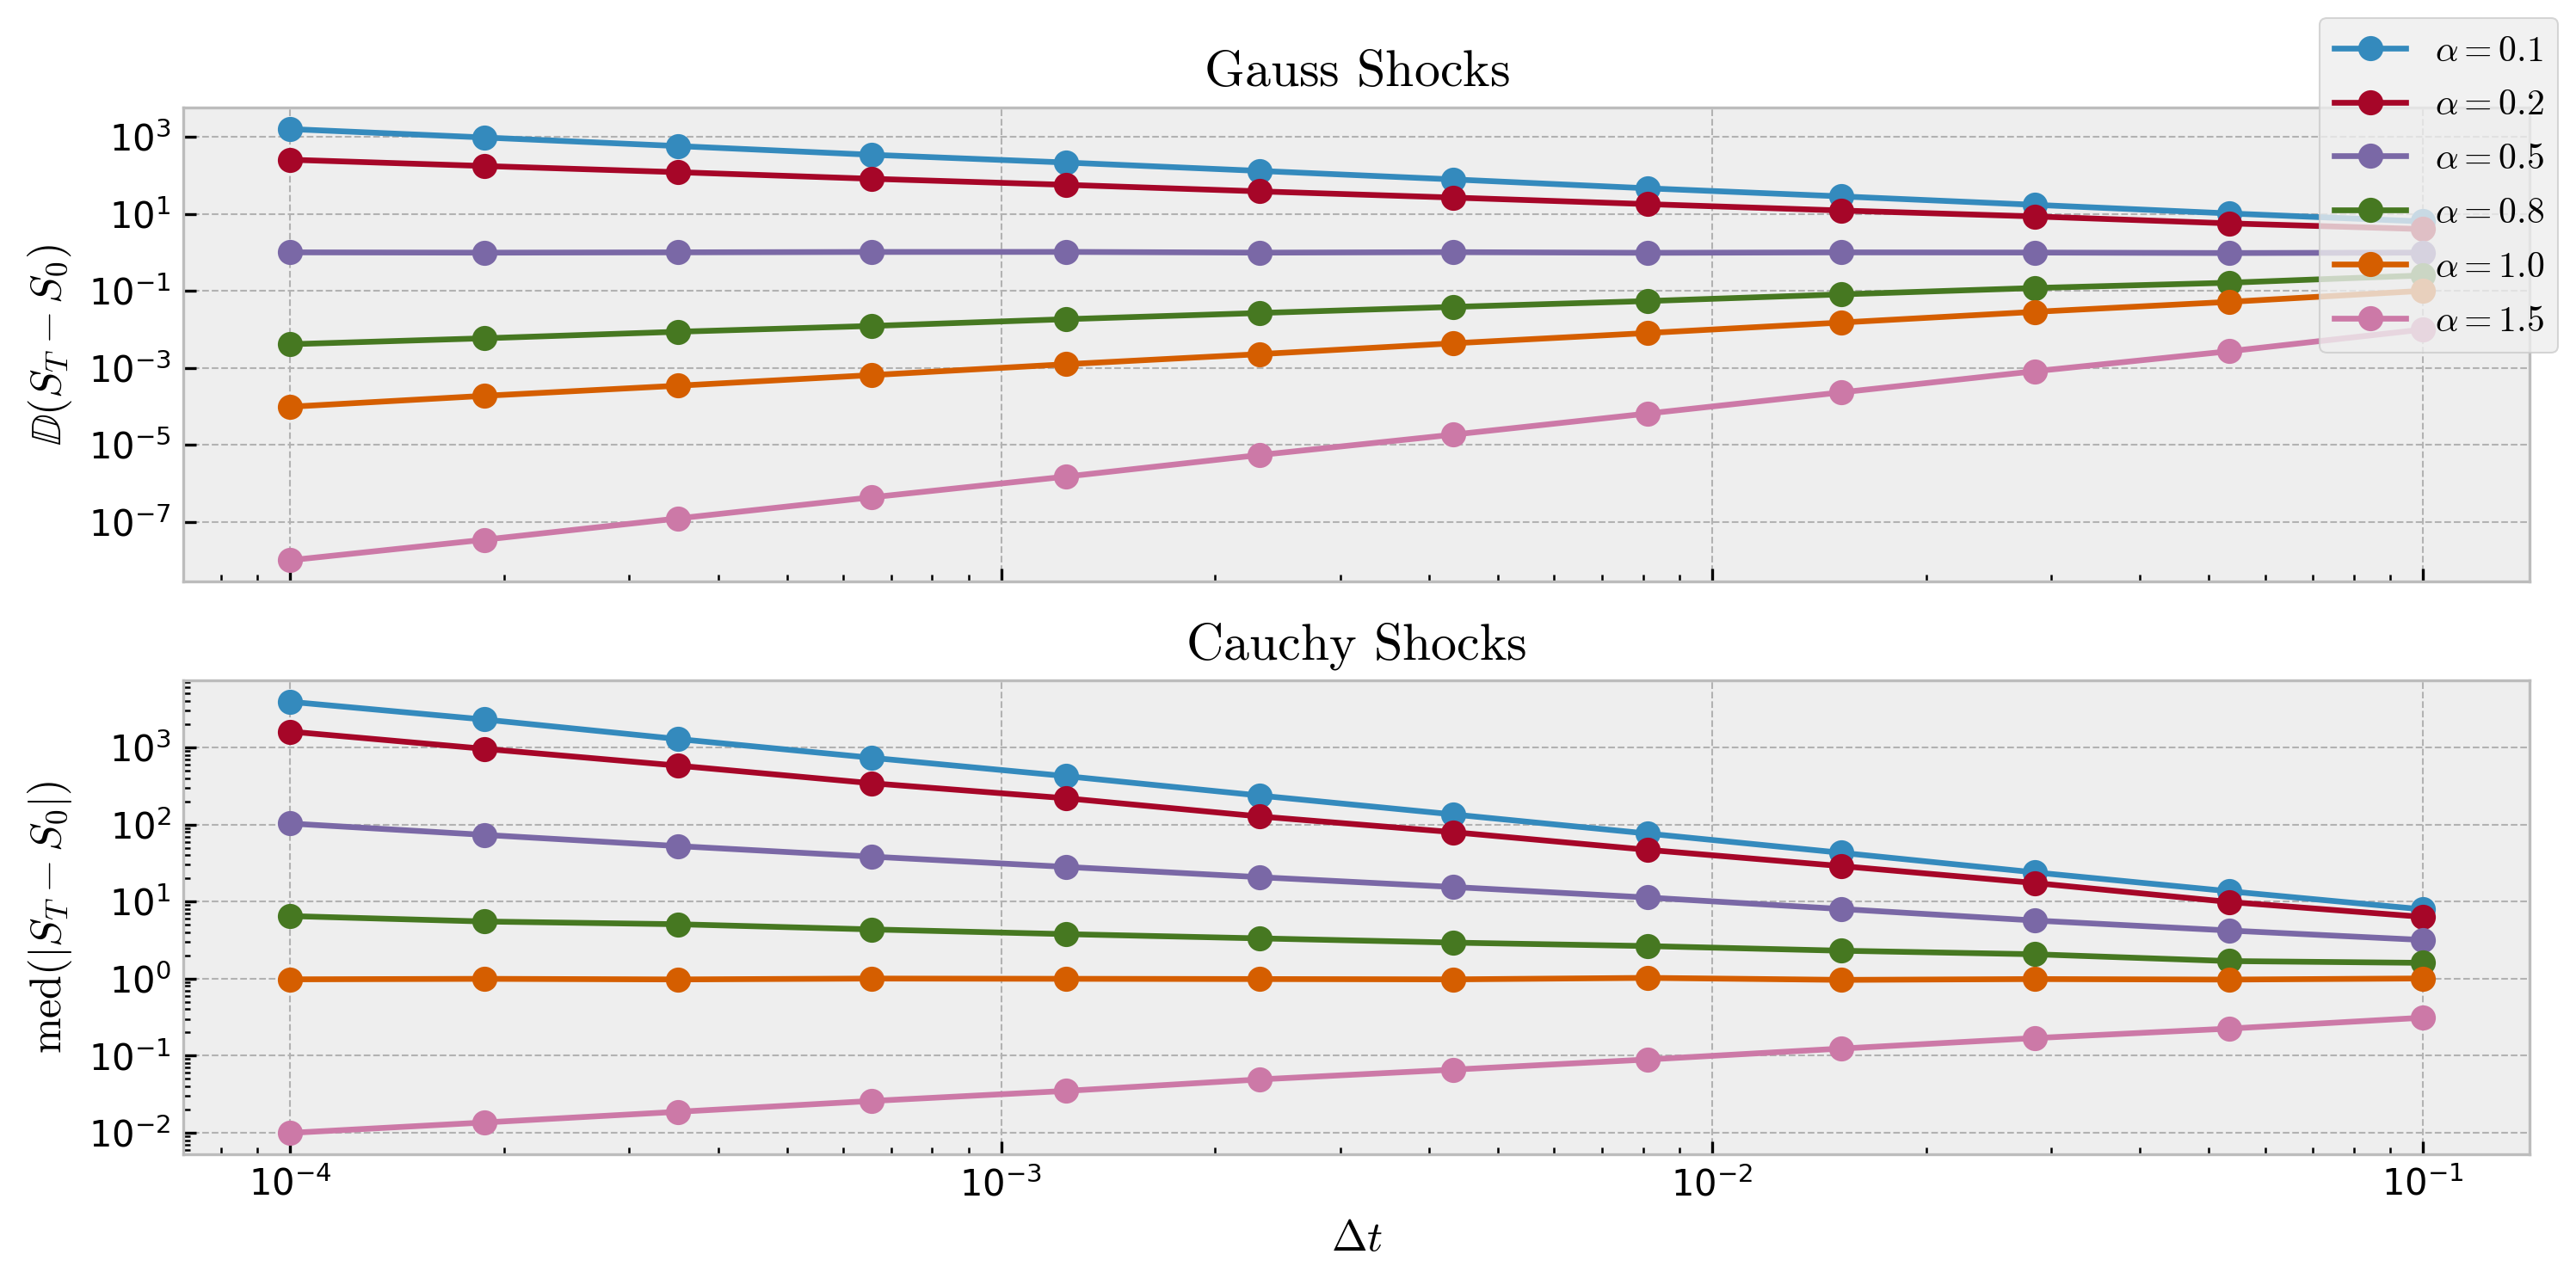

In [5]:
fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

for alpha in alphas:
    ax_top.loglog(dts, results_gauss[alpha]["vars"], "o-", label=rf"$\alpha = {alpha}$")
    ax_bot.loglog(dts, results_cauchy[alpha]["meds"], "o-")


ax_bot.set_xlabel(r"$\Delta t$")
ax_top.set_ylabel(r"$\mathbb{D}(S_T - S_0)$")
ax_bot.set_ylabel(r"$\text{med}(|S_T - S_0|)$")
ax_top.set_title(r"$\text{Gauss Shocks}$")
ax_bot.set_title(r"$\text{Cauchy Shocks}$")

fig.legend()
fig.tight_layout()

# Real Data


In [ ]:
import csv
import os
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone

from tqdm.auto import tqdm

# How many seconds each interval label corresponds to.
_INTERVAL_SECONDS = {
    "1s": 1,
    "5s": 5,
    "15s": 15,
    "1m": 60,
    "5m": 300,
    "15m": 900,
    "1h": 3600,
    "4h": 14400,
    "1d": 86400,
}


def _to_ms(value) -> int:
    """Convert a datetime or ISO-8601 string to a UTC millisecond timestamp."""
    if isinstance(value, str):
        value = datetime.fromisoformat(value)
    if value.tzinfo is None:
        value = value.replace(tzinfo=timezone.utc)
    return int(value.timestamp() * 1000)


def fetch_price_series(
    symbol: str,
    lookback: str = "1h",
    interval: str = "1s",
    *,
    start=None,
    end=None,
    chunk_s: int = 60,
    max_workers: int = 8,
    save_dir: str = "data",
    overwrite: bool = False,
    progress: bool = True,
) -> str:
    """Download trades from Binance in parallel and save a resampled price CSV.

    Args:
        symbol: Trading pair, e.g. "BTCUSDT", "ETHUSDT".
        lookback: How far back to pull from now (interval label, e.g. "1h", "1d").
            Ignored when ``start`` is given.
        interval: Bucket size for the output series (e.g. "1s", "1m", "1h").
        start: Optional range start (datetime or ISO-8601 string, UTC if naive).
        end: Optional range end (datetime or ISO-8601 string); defaults to now.
        chunk_s: Width of each parallel request window in seconds.
        max_workers: Number of concurrent requests.
        save_dir: Directory to write the CSV into.
        overwrite: Re-download even if the target CSV already exists.
        progress: Show a tqdm progress bar over the parallel requests.

    Returns:
        Path to the written (or existing) CSV file.
    """
    if interval not in _INTERVAL_SECONDS:
        raise ValueError(
            f"Unknown interval {interval!r}; choose from {list(_INTERVAL_SECONDS)}"
        )

    step_s = _INTERVAL_SECONDS[interval]
    os.makedirs(save_dir, exist_ok=True)

    # Resolve the time range: explicit start/end take priority over lookback.
    end_ms = _to_ms(end) if end is not None else int(time.time() * 1000)
    if start is not None:
        start_ms = _to_ms(start)
    else:
        if lookback not in _INTERVAL_SECONDS:
            raise ValueError(
                f"Unknown lookback {lookback!r}; choose from {list(_INTERVAL_SECONDS)}"
            )
        start_ms = end_ms - _INTERVAL_SECONDS[lookback] * 1000
    if start_ms >= end_ms:
        raise ValueError("start must be earlier than end")

    # Filename encodes symbol, interval and the (UTC) date range so distinct
    # requests don't clobber each other.
    tag = (
        f"{datetime.fromtimestamp(start_ms / 1000, tz=timezone.utc):%Y%m%dT%H%M%S}"
        f"-{datetime.fromtimestamp(end_ms / 1000, tz=timezone.utc):%Y%m%dT%H%M%S}"
    )
    file_path = os.path.join(save_dir, f"{symbol.lower()}_{interval}_{tag}.csv")

    if os.path.exists(file_path) and not overwrite:
        print(f"File already exists, skipping download: {file_path}")
        return file_path

    # Split the full window into chunks fetched concurrently.
    windows = [
        (s, min(s + chunk_s * 1000, end_ms))
        for s in range(start_ms, end_ms, chunk_s * 1000)
    ]

    def fetch_window(window: tuple[int, int]) -> list[dict]:
        win_start, win_end = window
        resp = requests.get(
            "https://api.binance.com/api/v3/aggTrades",
            params={
                "symbol": symbol,
                "startTime": win_start,
                "endTime": win_end,
                "limit": 1000,
            },
        )
        resp.raise_for_status()
        return resp.json()

    # Bucket trades into the requested interval (last price in each bucket wins).
    prices_by_bucket = {}
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [executor.submit(fetch_window, w) for w in windows]
        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc=f"{symbol} {interval}",
            unit="req",
            disable=not progress,
        ):
            for trade in future.result():
                bucket = (trade["T"] // 1000) // step_s
                prices_by_bucket[bucket] = float(trade["p"])

    if not prices_by_bucket:
        raise RuntimeError(f"No Binance trade data returned for {symbol}")

    buckets = sorted(prices_by_bucket)

    with open(file_path, "w", newline="") as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(["timestamp", "price"])
        last_price = None
        for bucket in range(buckets[0], buckets[-1] + 1):
            if bucket in prices_by_bucket:
                last_price = prices_by_bucket[bucket]
            if last_price is not None:
                ts = datetime.fromtimestamp(bucket * step_s, tz=timezone.utc)
                writer.writerow([ts.isoformat(), f"{last_price:.8f}"])

    print(f"Saved {symbol} {interval} price data to {file_path}")
    return file_path


file_path = fetch_price_series(
    "BTCUSDT", interval="1m", start="2026-05-01T00:00:00", end="2026-05-03T00:00:00"
)
# file_path = fetch_price_series(
# "BTCUSDT", interval="1m", start="2026-05-01T00:00:00", end="2026-06-01T00:00:00"
# )

File already exists, skipping download: data/btcusdt_1m_20260501T000000-20260503T000000.csv


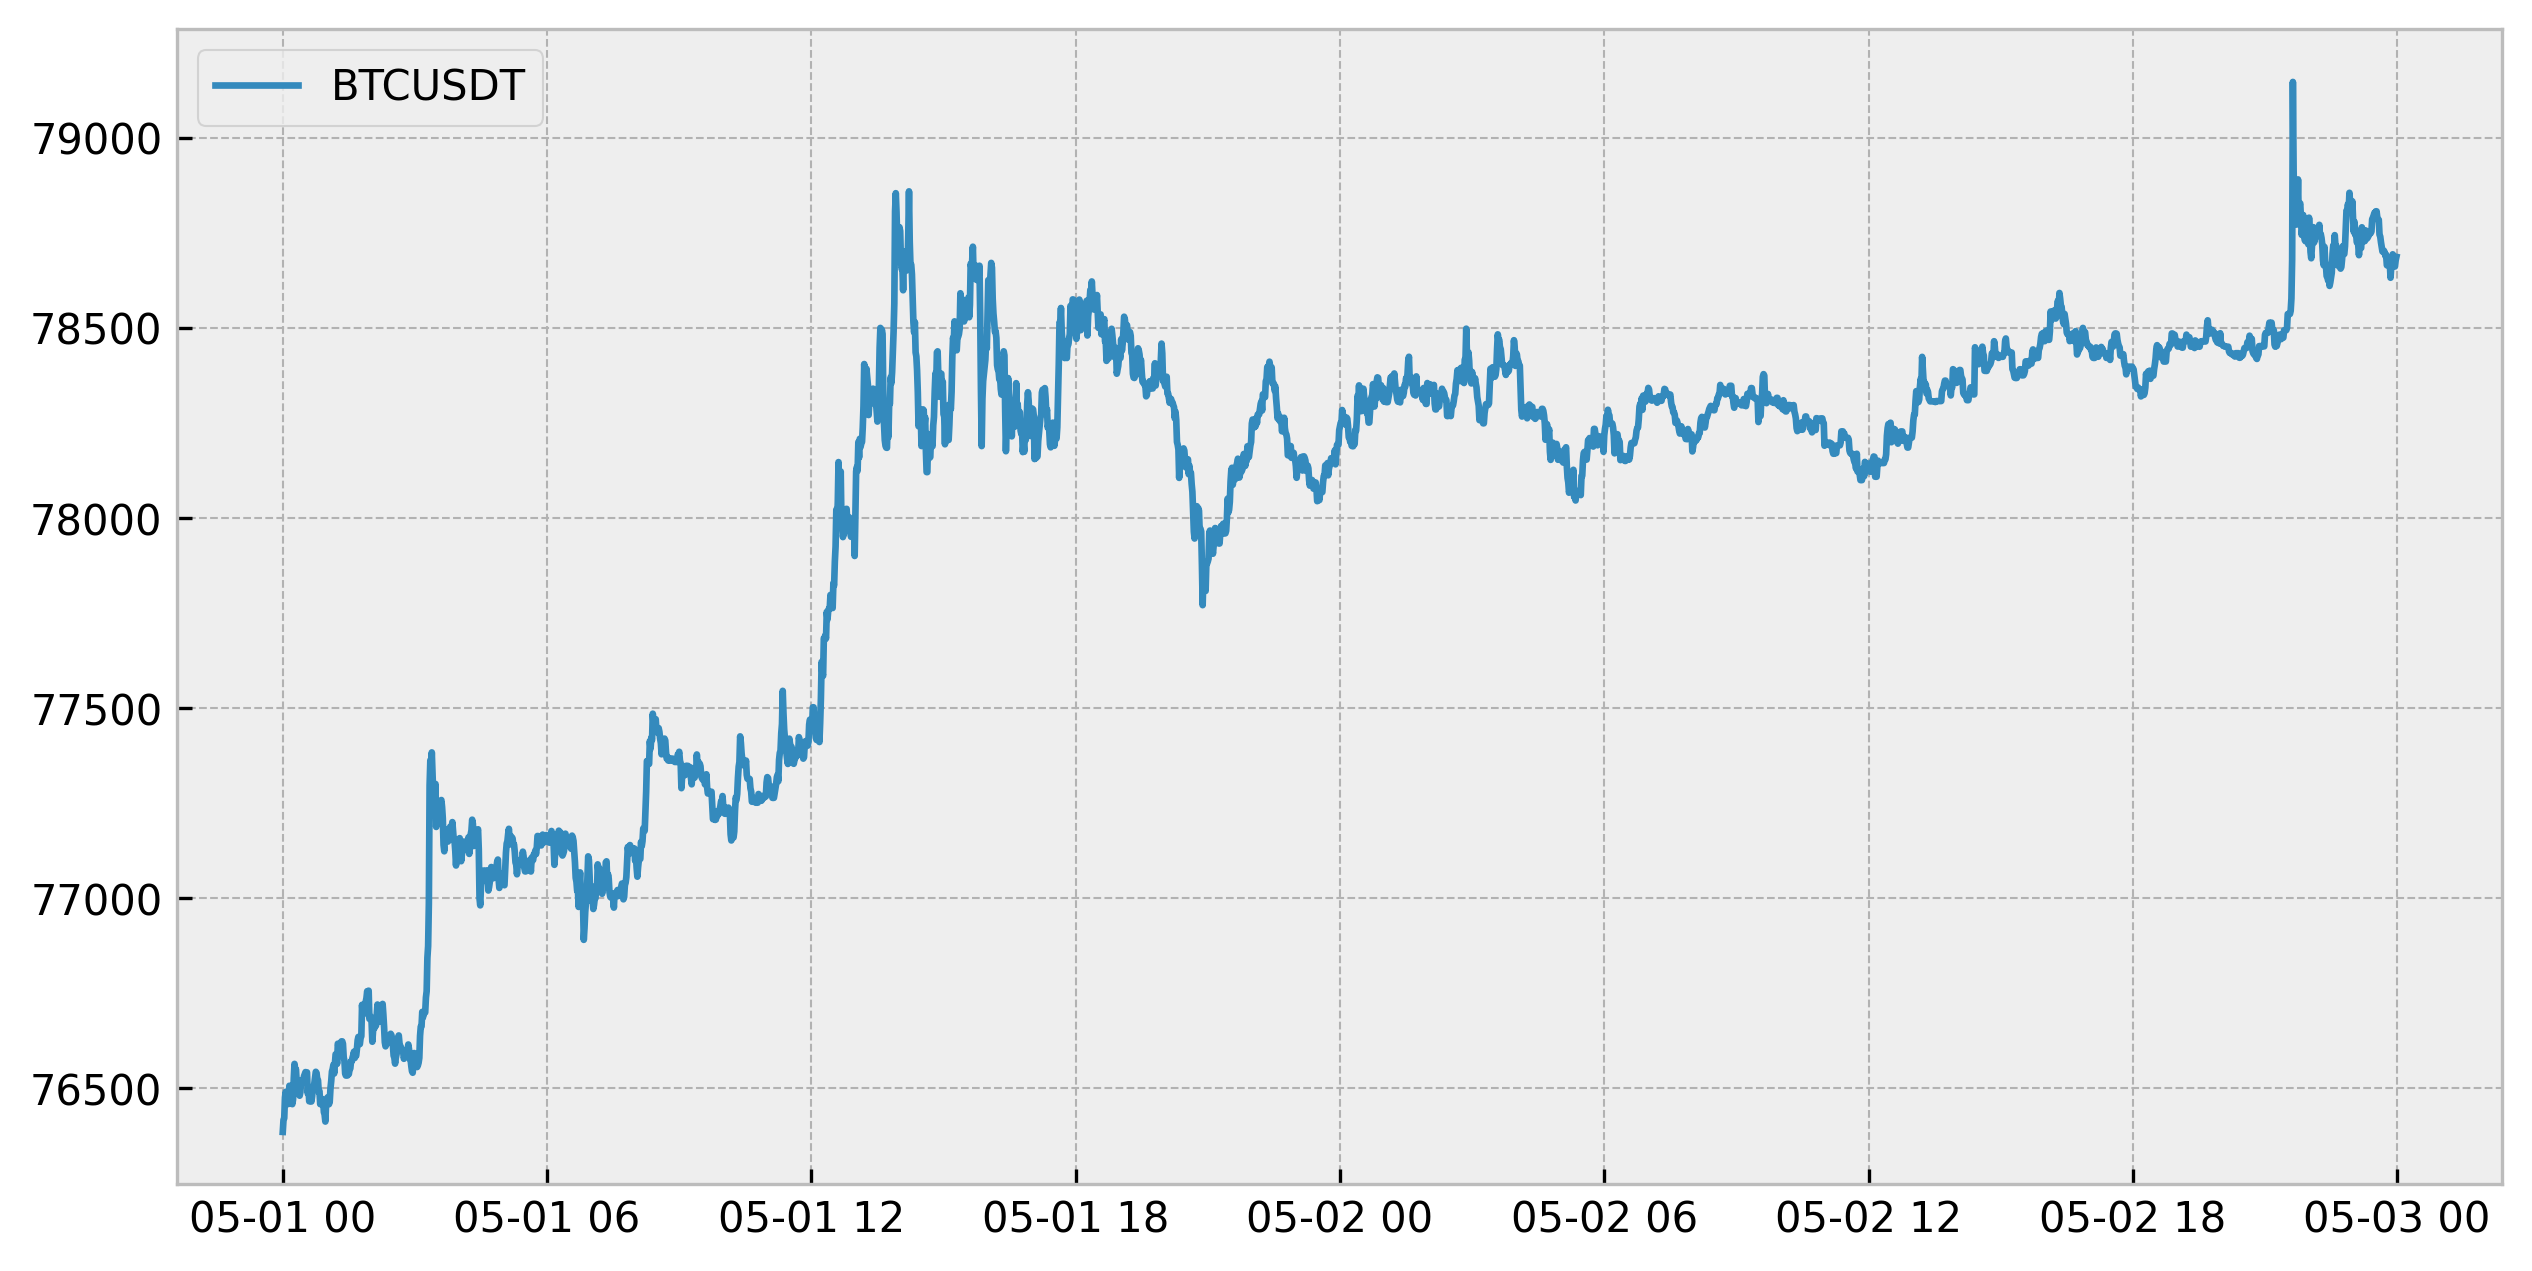

In [7]:
df = pd.read_csv(
    "./data/btcusdt_1m_20260501T000000-20260503T000000.csv",
    parse_dates=["timestamp"],
)

plt.figure()
plt.plot(df["timestamp"], df["price"], label="BTCUSDT")
plt.legend()
plt.show()